# Riesgo empírico frente a riesgo esperado

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 1, unidad 1 · Genera la figura de la lámina «Lo mismo, con números»

---

Este cuaderno genera la figura que se muestra en clase y, de paso, sirve como referencia
de lo que se le pedirá en el **taller 1**: un cuaderno que se ejecuta completo de cero, con
semillas y entorno declarados, con el protocolo de partición explicitado, y con una bitácora
que justifica las decisiones tomadas.

## Qué muestra

Ajustamos polinomios de grado creciente a una muestra de 30 observaciones y medimos dos cosas:

| Cantidad | Sobre qué se calcula | Qué le pasa al aumentar la capacidad |
|---|---|---|
| Riesgo empírico, $R_S(h)$ | los 30 casos de la muestra $S$ | **decrece siempre** |
| Riesgo esperado, $R_\mathcal{D}(h)$ | 2 000 casos nuevos de $\mathcal{D}$ | baja, toca un mínimo, y **vuelve a subir** |

El punto de la clase está en la segunda fila: **el riesgo empírico nunca le avisa que se pasó.**

## Una advertencia sobre este ejemplo

Aquí conocemos $\mathcal{D}$ porque la inventamos: los datos salen de
$y = \operatorname{sen}(2\pi x) + \varepsilon$ con $\varepsilon \sim N(0,\ 0{,}25^2)$.
Eso permite calcular $R_\mathcal{D}$ generando casos nuevos a voluntad.

**En un problema real esto es imposible.** No se puede muestrear de $\mathcal{D}$ a demanda;
por eso existen los protocolos de validación de la unidad 3, que estiman $R_\mathcal{D}$ con
los datos escasos que uno tiene. Este cuaderno es una simulación didáctica, no un protocolo.

## 1. Entorno

Se declara para que un tercero pueda reproducir el resultado exacto. Es el ítem 2 de la lista de cotejo de los talleres.

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

print("Python     ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy      ", np.__version__)
print("matplotlib ", matplotlib.__version__)

Python      3.12.14 | Darwin arm64
numpy       2.2.6
matplotlib  3.10.9


## 2. Parámetros

Todo lo que gobierna el resultado está aquí arriba, en un solo lugar y con nombre.
No hay números mágicos repartidos por el cuaderno.

In [2]:
SEMILLA = 7                 # fija el generador; cambiarla cambia los números, no la conclusión
N_ENTRENAMIENTO = 30        # tamaño de la muestra S
N_EVALUACION = 2000         # casos nuevos para estimar el riesgo esperado
SIGMA = 0.25                # desviación del ruido
GRADOS = range(1, 16)       # capacidad de la familia de hipótesis

def f_verdadera(x):
    """La función que genera los datos. En un problema real, desconocida."""
    return np.sin(2 * np.pi * x)

## 3. Datos

**Protocolo de partición.** Los dos conjuntos se generan por separado y en orden fijo a partir
del mismo generador. El de evaluación no participa en ningún ajuste: se usa una sola vez, al
final, para medir. Esto es lo que hace que la curva naranja signifique algo.

El orden de las llamadas al generador importa: alterarlo cambia los números. Por eso se
mantiene exactamente este orden y no se reordenan las celdas.

In [3]:
rng = np.random.default_rng(SEMILLA)

# Muestra S: es todo lo que "tenemos"
x_ent = np.sort(rng.uniform(0, 1, N_ENTRENAMIENTO))
y_ent = f_verdadera(x_ent) + rng.normal(0, SIGMA, N_ENTRENAMIENTO)

# Casos nuevos: solo para medir, nunca para ajustar
x_eval = np.sort(rng.uniform(0, 1, N_EVALUACION))
y_eval = f_verdadera(x_eval) + rng.normal(0, SIGMA, N_EVALUACION)

print(f"Muestra S:      {x_ent.size} casos")
print(f"Casos nuevos:   {x_eval.size} casos")

Muestra S:      30 casos
Casos nuevos:   2000 casos


## 4. Ajuste y medición

Un polinomio por cada grado. `np.polyfit` es mínimos cuadrados ordinarios: minimiza
exactamente el riesgo empírico con pérdida cuadrática, que es la definición de ERM
para esta familia de hipótesis.

**El ajuste ve únicamente `x_ent` e `y_ent`.** Los datos de evaluación no entran en `polyfit`.
Ese es el ítem 4 de la lista de cotejo.

**Métrica.** Error cuadrático medio. Se justifica porque es el promedio muestral de la misma
pérdida que se está minimizando: así el riesgo empírico y el riesgo esperado son la misma
cantidad medida sobre poblaciones distintas, que es justo la comparación que interesa.

In [4]:
def error_cuadratico_medio(coef, x, y):
    return float(np.mean((np.polyval(coef, x) - y) ** 2))

riesgo_empirico, riesgo_esperado = [], []

for grado in GRADOS:
    coef = np.polyfit(x_ent, y_ent, grado)          # solo entrenamiento
    riesgo_empirico.append(error_cuadratico_medio(coef, x_ent, y_ent))
    riesgo_esperado.append(error_cuadratico_medio(coef, x_eval, y_eval))

grado_optimo = list(GRADOS)[int(np.argmin(riesgo_esperado))]
print(f"Mínimo del riesgo esperado en el grado {grado_optimo}: {min(riesgo_esperado):.3f}")

Mínimo del riesgo esperado en el grado 6: 0.068


## 5. Tabla

Estos son, exactamente, los valores que la lámina «Lo mismo, con números» toma de este cuaderno.

In [5]:
print(f"{'grado':>6} {'R_S (empírico)':>16} {'R_D (esperado)':>16}   ")
print("-" * 46)
for g, e, v in zip(GRADOS, riesgo_empirico, riesgo_esperado):
    marca = "  <- mínimo de R_D" if g == grado_optimo else ""
    print(f"{g:>6} {e:>16.3f} {v:>16.3f}{marca}")

 grado   R_S (empírico)   R_D (esperado)   
----------------------------------------------
     1            0.286            0.279
     2            0.285            0.280
     3            0.043            0.070
     4            0.042            0.071
     5            0.040            0.069
     6            0.040            0.068  <- mínimo de R_D
     7            0.038            0.073
     8            0.036            0.078
     9            0.035            0.076
    10            0.034            0.097
    11            0.033            0.092
    12            0.029            0.135
    13            0.029            0.129
    14            0.029            0.137
    15            0.029            0.135


## 6. Figura

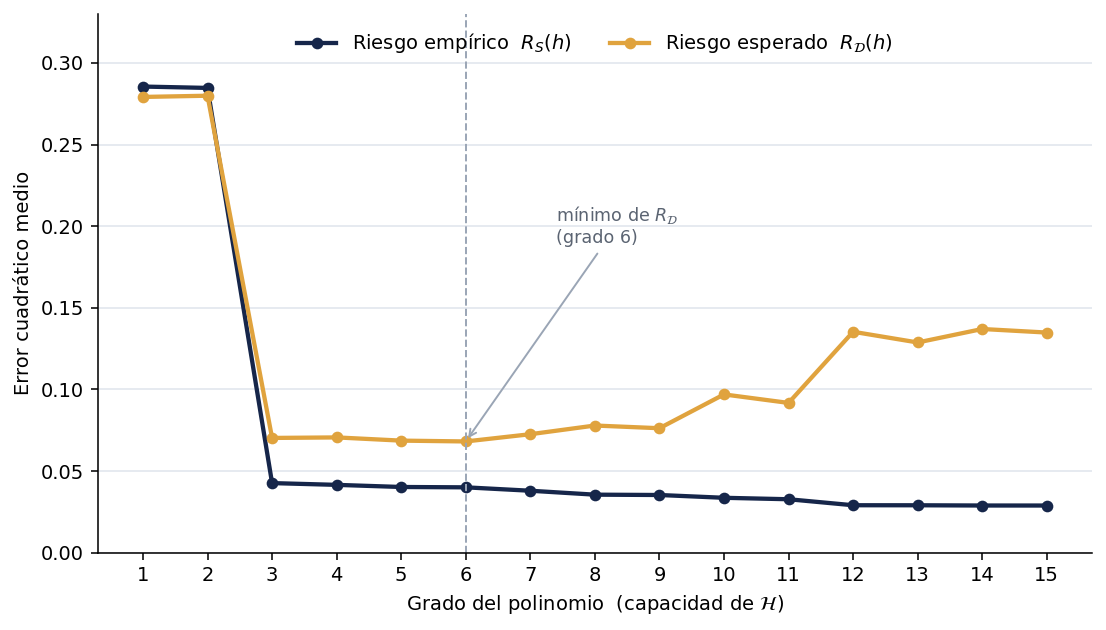

In [6]:
#| label: fig-riesgo
#| fig-cap: "Riesgo empírico y riesgo esperado frente a la capacidad."
fig, ax = plt.subplots(figsize=(8, 4.6), dpi=140)

ax.plot(list(GRADOS), riesgo_empirico, "o-", lw=2.2, ms=5,
        color="#16264A", label="Riesgo empírico  $R_S(h)$")
ax.plot(list(GRADOS), riesgo_esperado, "o-", lw=2.2, ms=5,
        color="#E0A33E", label="Riesgo esperado  $R_\\mathcal{D}(h)$")

ax.axvline(grado_optimo, color="#9AA5B5", ls="--", lw=1)
ax.annotate(f"mínimo de $R_\\mathcal{{D}}$\n(grado {grado_optimo})",
            xy=(grado_optimo, min(riesgo_esperado)), xytext=(grado_optimo + 1.4, 0.19),
            fontsize=9, color="#5B6472",
            arrowprops=dict(arrowstyle="->", color="#9AA5B5", lw=1))

ax.set_xlabel("Grado del polinomio  (capacidad de $\\mathcal{H}$)")
ax.set_ylabel("Error cuadrático medio")
ax.set_xticks(list(GRADOS))
ax.set_ylim(0, 0.33)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6EAF0", lw=1)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", ncol=2)

fig.tight_layout()
fig.savefig("riesgo_empirico_vs_esperado.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. La curva naranja también es una estimación

En clase se advierte que $R_\mathcal{D}$ tampoco es un número exacto: se calculó sobre
**una** realización de $S$. Otra muestra da otra curva.

Lo verificamos repitiendo todo con veinte semillas. Es el ítem 5 de la lista de cotejo:
reportar variabilidad, no solo la media.

In [7]:
def una_realizacion(semilla):
    r = np.random.default_rng(semilla)
    xe = np.sort(r.uniform(0, 1, N_ENTRENAMIENTO))
    ye = f_verdadera(xe) + r.normal(0, SIGMA, N_ENTRENAMIENTO)
    xv = np.sort(r.uniform(0, 1, N_EVALUACION))
    yv = f_verdadera(xv) + r.normal(0, SIGMA, N_EVALUACION)
    return [error_cuadratico_medio(np.polyfit(xe, ye, g), xv, yv) for g in GRADOS]

repeticiones = np.array([una_realizacion(s) for s in range(1, 21)])

media, desv = repeticiones.mean(axis=0), repeticiones.std(axis=0, ddof=1)
print(f"{'grado':>6} {'media':>12} {'media - 1 d.e.':>16} {'mediana':>12}")
print("-" * 50)
for i, g in enumerate(GRADOS):
    print(f"{g:>6} {media[i]:>12.3f} {media[i]-desv[i]:>16.3f} {np.median(repeticiones[:, i]):>12.3f}")

 grado        media   media - 1 d.e.      mediana
--------------------------------------------------
     1        0.278            0.257        0.272
     2        0.286            0.258        0.278
     3        0.075            0.068        0.072
     4        0.083            0.062        0.078
     5        0.095            0.023        0.077
     6        0.122           -0.051        0.084
     7        0.381           -0.913        0.086
     8        0.164           -0.110        0.098
     9        1.446           -4.551        0.100
    10        4.278          -13.628        0.132
    11        2.086           -5.534        0.172
    12       69.295         -224.860        0.366
    13       86.518         -167.569        0.460
    14     2750.332        -8272.464        1.603
    15     2059.833        -6203.258        8.261


**Mire la tercera columna.** A partir del grado 5, «media menos una desviación estándar» es
**negativa**, y un error cuadrático medio no puede serlo. Eso no es un error de cálculo: es la
señal de que la distribución de $R_\mathcal{D}$ sobre muestras es fuertemente asimétrica y de
cola pesada. Con capacidad alta y $n = 30$, el ajuste polinomial es numéricamente inestable, y
basta una realización desafortunada para que el riesgo se dispare varios órdenes de magnitud.

Resumir eso con media y desviación estándar es incorrecto: ambos estadísticos suponen implícitamente
una dispersión simétrica y son arrastrados por los valores extremos. Corresponde usar **mediana y
rango intercuartílico**, que no lo son, y una **escala logarítmica**, porque el rango cubre varios
órdenes de magnitud.

Este tropiezo no es un accidente del cuaderno: es exactamente el tipo de decisión que se le va a
pedir justificar en la bitácora de cada taller.

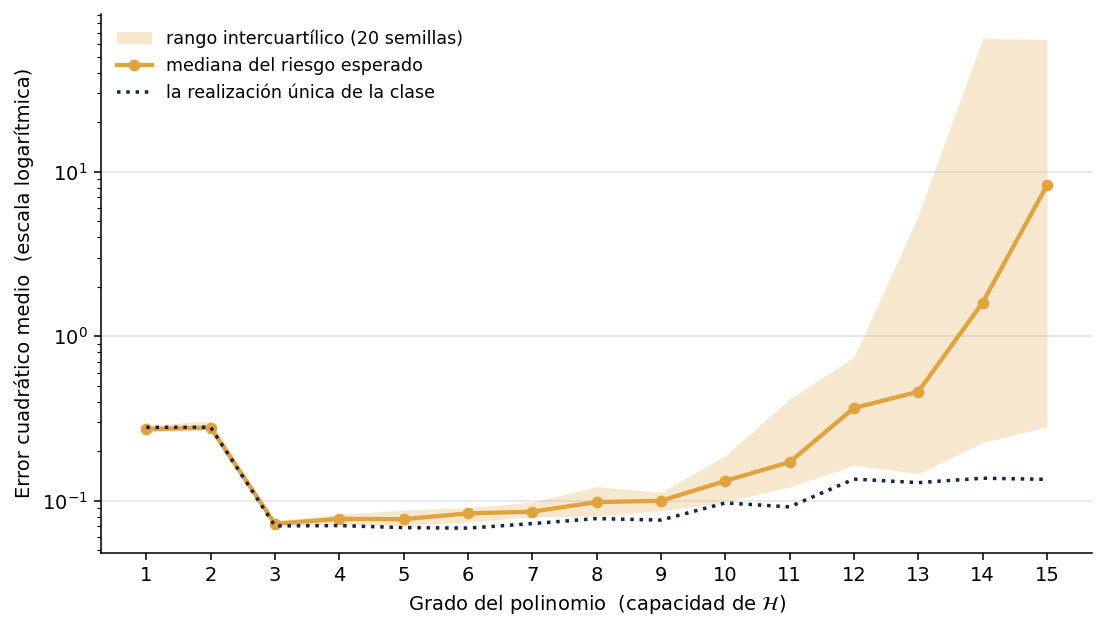

Grado que minimiza la mediana de 20 semillas:  3
Grado que minimiza la realización de la clase:  6


In [8]:
#| label: fig-variabilidad
#| fig-cap: "Mediana y rango intercuartílico del riesgo esperado sobre 20 semillas."
mediana = np.median(repeticiones, axis=0)
q25, q75 = np.percentile(repeticiones, [25, 75], axis=0)

fig, ax = plt.subplots(figsize=(8, 4.6), dpi=140)
ax.fill_between(list(GRADOS), q25, q75, color="#E0A33E", alpha=0.25, lw=0,
                label="rango intercuartílico (20 semillas)")
ax.plot(list(GRADOS), mediana, "o-", lw=2.2, ms=5, color="#E0A33E",
        label="mediana del riesgo esperado")
ax.plot(list(GRADOS), riesgo_esperado, ":", lw=1.8, color="#16264A",
        label="la realización única de la clase")

ax.set_yscale("log")
ax.set_xlabel("Grado del polinomio  (capacidad de $\\mathcal{H}$)")
ax.set_ylabel("Error cuadrático medio  (escala logarítmica)")
ax.set_xticks(list(GRADOS))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E6EAF0", lw=1)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()
fig.savefig("variabilidad_del_riesgo_estimado.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Grado que minimiza la mediana de 20 semillas:  {list(GRADOS)[int(np.argmin(mediana))]}")
print(f"Grado que minimiza la realización de la clase:  {grado_optimo}")

**Lea con cuidado la última salida.** Si los dos grados no coinciden, tiene delante el argumento
de la clase en su forma más incómoda: elegir la capacidad mirando **una sola** estimación del riesgo
lo lleva a un grado que la repetición no confirma. El rango intercuartílico dice cuánta de esa
diferencia es señal y cuánta es la muestra que le tocó.

Y note además que la banda se ensancha con la capacidad. Los modelos flexibles no solo tienden a un
riesgo mayor: tienen un riesgo **menos predecible**. Es el compromiso sesgo-varianza de la semana 3,
visto por el lado de la varianza.

## 8. Bitácora

Es el documento que se entrega junto con cada taller. Una página, con las decisiones y su razón.

**Decisiones tomadas**

1. *Pérdida cuadrática y error cuadrático medio como métrica.* El problema es de regresión con
   ruido gaussiano y errores simétricos: no hay razón para penalizar de forma distinta
   sobreestimar y subestimar.
2. *Grados 1 a 15.* Con $n = 30$, un polinomio de grado 29 interpola exactamente y el riesgo
   empírico cae a cero. Cortar en 15 mantiene la figura legible sin cambiar la conclusión.
3. *2 000 casos de evaluación.* Suficientes para que el error de estimación de $R_\mathcal{D}$
   sea pequeño frente a la diferencia que se quiere mostrar. La sección 7 lo verifica.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró estimar $R_\mathcal{D}$ con validación cruzada de 5 pliegues sobre los mismos 30
puntos, en vez de generar casos nuevos. **Se descartó** porque habría mezclado dos ideas en la
misma figura: la distinción entre riesgo empírico y esperado, que es el contenido de hoy, y la
estimación del riesgo con datos escasos, que es el contenido de la semana 7. Generando casos
nuevos, la curva naranja es lo más parecido a $R_\mathcal{D}$ que se puede tener, y la lámina
dice una sola cosa.

Ese ejercicio —rehacer esta figura con validación cruzada y comparar— es un buen punto de
partida para el taller 3.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del módulo.

## 9. Verificación

Un cuaderno reproducible debe fallar ruidosamente si deja de reproducir. Esta celda
compara la salida con los valores registrados cuando el cuaderno se validó.

In [9]:
REFERENCIA_EMPIRICO = [0.286, 0.285, 0.043, 0.042, 0.040, 0.040, 0.038, 0.036,
                      0.035, 0.034, 0.033, 0.029, 0.029, 0.029, 0.029]
REFERENCIA_ESPERADO = [0.279, 0.280, 0.070, 0.071, 0.069, 0.068, 0.073, 0.078,
                      0.076, 0.097, 0.092, 0.135, 0.129, 0.137, 0.135]

np.testing.assert_allclose(np.round(riesgo_empirico, 3), REFERENCIA_EMPIRICO, atol=1e-9)
np.testing.assert_allclose(np.round(riesgo_esperado, 3), REFERENCIA_ESPERADO, atol=1e-9)
print("El cuaderno reproduce los valores de referencia.")

El cuaderno reproduce los valores de referencia.
